### Adult dataset: EDA

All 48,842 rows (official train + test sets). To re-run, put `adult.data` and `adult.test` in `data/`.

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

from preprocessing import FEATURES, load_adult

train, test = load_adult()
df = pd.concat([train, test], ignore_index=True)

##### Class balance

In [18]:
rate = df["income"].mean()
print(f"{df['income'].sum():,} of {len(df):,} rows are >50K ({rate:.1%})")
print(f"Always predicting <=50K gets {1 - rate:.1%} accuracy")

11,687 of 48,842 rows are >50K (23.9%)
Always predicting <=50K gets 76.1% accuracy


Any model has to beat this. On the test set alone, the bar is 76.4%.

##### Missing values

In [19]:
unknown = df[FEATURES].eq("Unknown")
print(unknown.sum()[lambda s: s > 0].to_string(), "\n")

missing = unknown.any(axis=1)
print(f"Rows with a missing value: {missing.sum():,} ({missing.mean():.1%})")
print(f"Share >50K: {df.loc[missing, 'income'].mean():.1%} with a missing value, "
      f"{df.loc[~missing, 'income'].mean():.1%} without")

workclass         2799
occupation        2809
native-country     857 

Rows with a missing value: 3,620 (7.4%)
Share >50K: 13.2% with a missing value, 24.8% without


Keep these rows, with `Unknown` as a category: they're much less likely to be `>50K`, so dropping them would bias the data.

##### Numeric features

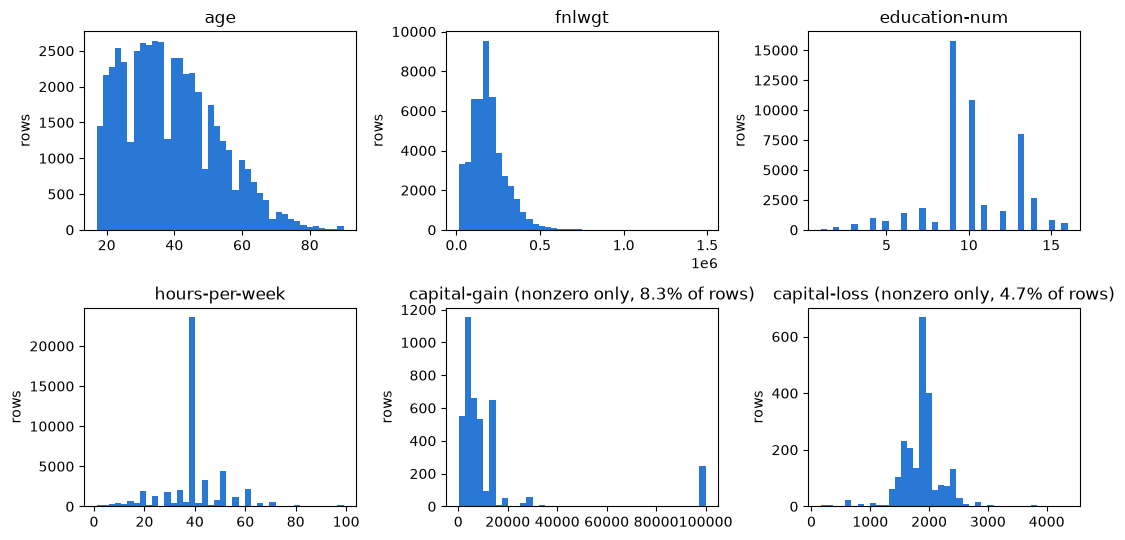

In [20]:
columns = ["age", "fnlwgt", "education-num", "hours-per-week", "capital-gain", "capital-loss"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, col in zip(axes.flat, columns):
    values = df[col]
    title = col
    if col.startswith("capital"):
        title = f"{col} (nonzero only, {(values > 0).mean():.1%} of rows)"
        values = values[values > 0]
    ax.hist(values, bins=40, color="#2a78d6")
    ax.set_title(title)
    ax.set_ylabel("rows")
fig.tight_layout()
plt.show()

The capital columns are mostly zero, so `onehot` applies `log1p` to them.

##### Share of >50K by category

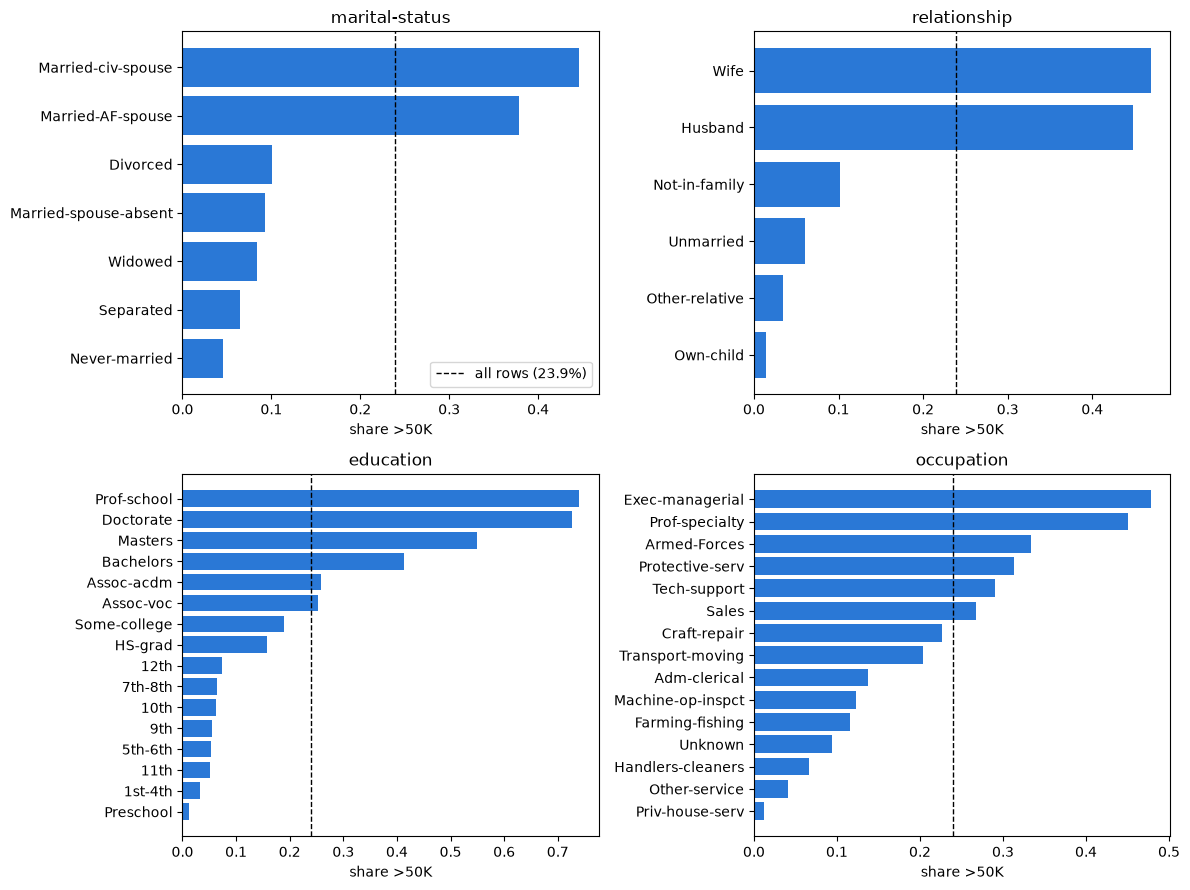

In [21]:
rate = df["income"].mean()
columns = ["marital-status", "relationship", "education", "occupation"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, columns):
    share = df.groupby(col)["income"].mean().sort_values()
    ax.barh(share.index, share.values, color="#2a78d6")
    ax.axvline(rate, color="black", linestyle="--", linewidth=1, label=f"all rows ({rate:.1%})")
    ax.set_title(col)
    ax.set_xlabel("share >50K")
axes[0, 0].legend()
fig.tight_layout()
plt.show()

Being married, a graduate degree and managerial or professional jobs go with >50K; never-married people and `Own-child` almost never are.

##### Education vs education-num

In [22]:
order = df.groupby("education")["education-num"].first().sort_values().index
table = pd.crosstab(df["education"], df["education-num"]).loc[order]
print(table.to_string())

education-num  1    2    3    4    5     6     7    8      9      10    11    12    13    14   15   16
education                                                                                             
Preschool      83    0    0    0    0     0     0    0      0      0     0     0     0     0    0    0
1st-4th         0  247    0    0    0     0     0    0      0      0     0     0     0     0    0    0
5th-6th         0    0  509    0    0     0     0    0      0      0     0     0     0     0    0    0
7th-8th         0    0    0  955    0     0     0    0      0      0     0     0     0     0    0    0
9th             0    0    0    0  756     0     0    0      0      0     0     0     0     0    0    0
10th            0    0    0    0    0  1389     0    0      0      0     0     0     0     0    0    0
11th            0    0    0    0    0     0  1812    0      0      0     0     0     0     0    0    0
12th            0    0    0    0    0     0     0  657      0      0     

Each education level has exactly one number: `education-num` is a one-to-one function of `education`.

##### Relationship vs sex and marital status

In [23]:
print(pd.crosstab(df["relationship"], df["sex"]).to_string(), "\n")
print(pd.crosstab(df["relationship"], df["marital-status"]).to_string())

sex             Female   Male
relationship                 
Husband              1  19715
Not-in-family     5870   6713
Other-relative     689    817
Own-child         3376   4205
Unmarried         3928   1197
Wife              2328      3 

marital-status  Divorced  Married-AF-spouse  Married-civ-spouse  Married-spouse-absent  Never-married  Separated  Widowed
relationship                                                                                                             
Husband                0                 12               19704                      0              0          0        0
Not-in-family       3628                  0                  23                    330           7114        637      851
Other-relative       181                  1                 201                     54            920         79       70
Own-child            455                  1                 143                     61           6750        146       25
Unmarried           2369  

`Husband` and `Wife` almost fix `sex` and always mean married: a strong dependence, but not a perfect one.